## Load data and stratified train-test split 80% - 20%

First, I load the prepared Ames Housing dataset, which contains 2,930 houses and 333 features. The target variable is `PriceClass`, which represents the six price categories we want to predict.

I split the data into training (80%) and test (20%) sets. I use stratification (`stratify=y`) to make sure that all six price classes are represented in approximately the same proportions in both sets. This is especially important because the classes are imbalanced and some of them have considerably fewer observations.

I use `random_state=42` to make the split reproducible.

The training set will be used for training and cross-validation, while the test set will remain separate and will only be used for the final evaluation.


In [2]:
import xgboost, optuna, plotly
print(xgboost.__version__, optuna.__version__, plotly.__version__)
from lab2_utils import get_data, get_split, CLASS_NAMES

X, y = get_data()
X_train, X_test, y_train, y_test = get_split(X, y)
print("X:", X.shape)
print(y_train.value_counts().sort_index())
print(y_test.value_counts().sort_index())


3.4.1 5.0.0 7.1.0
X: (2930, 333)
PriceClass
0    189
1    407
2    830
3    549
4    318
5     51
Name: count, dtype: int64
PriceClass
0     48
1    102
2    207
3    137
4     79
5     13
Name: count, dtype: int64



## 2. Stratified 5-Fold Cross-Validation

To get a better idea of how the model performs on different subsets of the data, I use stratified 5-fold cross-validation on the training set.

The training data is divided into five folds. In each iteration, four folds are used for training and the remaining one for validation. This process is repeated five times, so each fold is used for validation once.

I use **macro-averaged F1-score (macro-F1)** as the evaluation metric because we have six imbalanced price classes. For each fold, the F1-score is calculated separately for all six classes and then averaged, giving every class equal importance regardless of how many houses it contains.

After completing all five iterations, I look at:

- **Individual fold scores:** Macro-F1 obtained in each of the five iterations.
- **Mean macro-F1:** Average of the five fold scores, giving an idea of the model's overall performance.
- **Standard deviation:** Shows how much the scores vary between folds. A lower value means that the model performs more consistently across the different subsets.


In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

# Define 5-fold stratified cross-validation
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the baseline model using 5-fold CV
cv_scores = cross_val_score(
    XGBClassifier(random_state=42),
    X_train,
    y_train,
    cv=cv5,
    scoring="f1_macro"
)

print("Individual fold scores:", cv_scores.round(3))
print("Mean macro-F1:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Individual fold scores: [0.752 0.721 0.704 0.737 0.7  ]
Mean macro-F1: 0.722
Standard deviation: 0.02




## 3. Training the Baseline Model and Generating Predictions

After cross-validation, I will train a new XGBoost model using the entire training set (80% of the data). The previous five models were only used to evaluate the performance through cross-validation. Now I want to have one trained model that I can use for the actual evaluation.

After training, I will make predictions on the test set (20% of the data), which the model has not seen before.

I will use two types of predictions:
- `y_pred`: the predicted price class for each house.
- `y_prob`: the predicted probabilities for each of the six price classes.

I need the predicted classes for the evaluation metrics and confusion matrix, while the probabilities will be used for the ROC and Precision-Recall curves and finding the best classification thresholds.


In [4]:
baseline = XGBClassifier(random_state=42)

baseline.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklear

In [5]:
from sklearn.metrics import f1_score

y_pred = baseline.predict(X_test)

test_macro_f1 = f1_score(y_test, y_pred, average="macro")

print("Test macro-F1:", round(test_macro_f1, 3))

Test macro-F1: 0.748



## 4. Evaluation Metrics

Now I want to evaluate how well the model predicts the price classes on the test set. I use the predictions from the baseline model and compare them with the actual price classes.

I calculate the following metrics:

- **Accuracy:** The proportion of houses for which the predicted price class is correct.
- **Precision:** How many of the houses predicted to belong to a certain class actually belong to that class.
- **Recall:** How many of the actual houses in a class were correctly identified by the model.
- **F1-score:** Combines precision and recall into one metric.

Since the dataset is imbalanced, I use macro-averaging for precision, recall and F1. This means that all six price classes have equal importance when calculating the average.

I also look at the individual class scores to see which price categories are more difficult for the model to predict.


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Generate predictions
y_pred = baseline.predict(X_test)
y_prob = baseline.predict_proba(X_test)

# Calculate evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Macro Precision:", round(precision_score(y_test, y_pred, average="macro"), 3))
print("Macro Recall:", round(recall_score(y_test, y_pred, average="macro"), 3))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 3))

# Individual metrics for each price class
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0
))

Accuracy: 0.782
Macro Precision: 0.778
Macro Recall: 0.727
Macro F1: 0.748

Classification Report:
              precision    recall  f1-score   support

       <100k      0.762     0.667     0.711        48
    100–130k      0.676     0.676     0.676       102
    130–180k      0.783     0.855     0.818       207
    180–250k      0.847     0.766     0.805       137
    250–400k      0.819     0.861     0.840        79
       ≥400k      0.778     0.538     0.636        13

    accuracy                          0.782       586
   macro avg      0.778     0.727     0.748       586
weighted avg      0.782     0.782     0.780       586




## 5. Confusion Matrix

Next, I want to see which price classes the model confuses with each other. For this, I create a confusion matrix comparing the actual price classes with the predicted ones.

The confusion matrix has six rows and six columns because we have six possible classes.

- **Rows:** Actual price classes.
- **Columns:** Predicted price classes.
- **Diagonal:** Houses that were classified correctly.
- **Off-diagonal:** Houses that were assigned to the wrong price class.

This should help me see whether the model mainly confuses neighboring price categories or also makes larger classification errors.


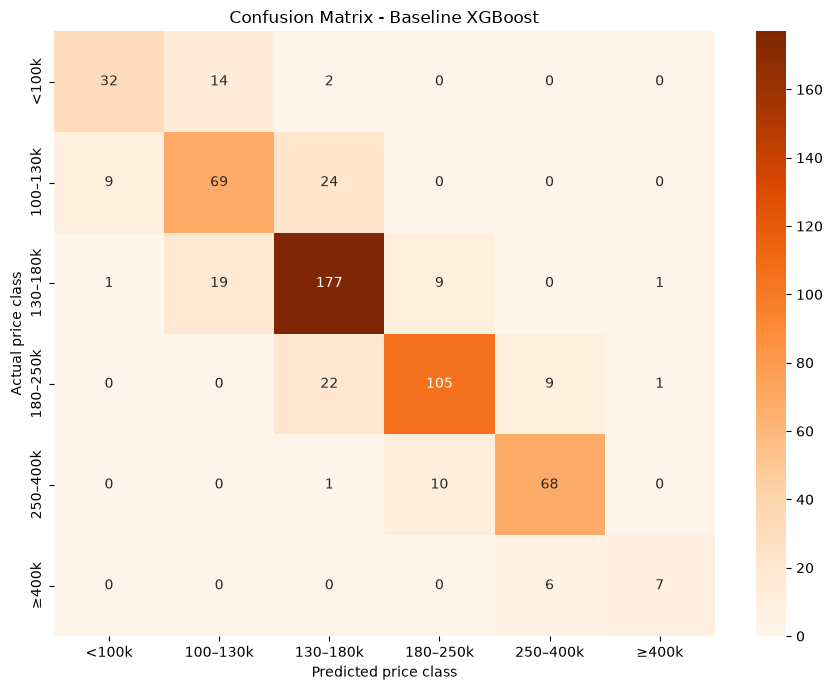

In [7]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(CLASS_NAMES))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted price class")
plt.ylabel("Actual price class")
plt.title("Confusion Matrix - Baseline XGBoost")
plt.tight_layout()
plt.show()


## 6. ROC Curve

I also want to investigate how well the model can distinguish between the different price classes using ROC curves.

Since this is a multiclass classification problem, I use the One-vs-Rest (OvR) approach. This means that I evaluate each price class separately, treating it as the positive class and all the other classes as negative.

For each class, I calculate:
- **True Positive Rate (TPR):** The proportion of actual positive observations correctly identified.
- **False Positive Rate (FPR):** The proportion of negative observations incorrectly classified as positive.
- **AUC:** The area under the ROC curve, which gives an overall measure of how well the model separates the class from the others.

An AUC closer to 1 indicates better class separation, while a value around 0.5 indicates performance similar to random ranking.


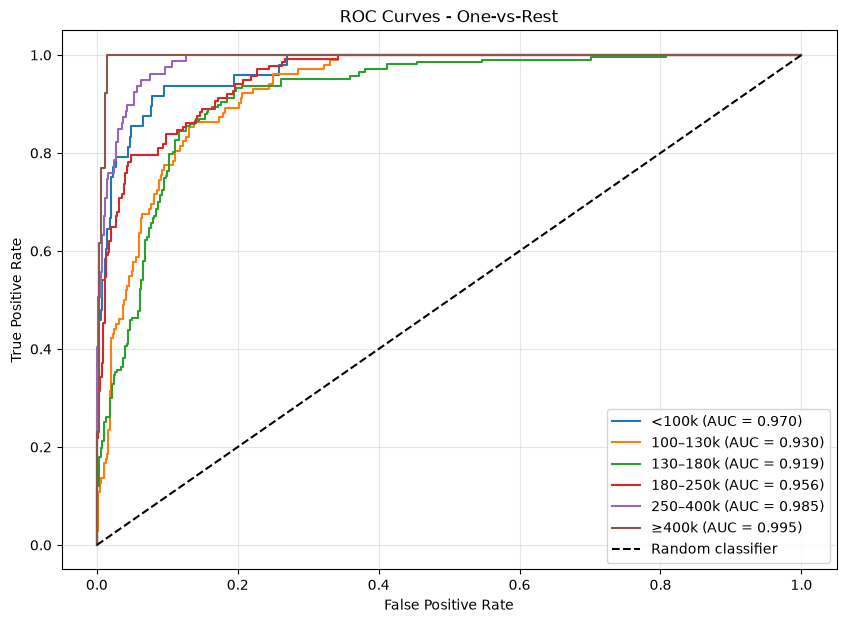

In [8]:
import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Convert the actual classes into binary format (One-vs-Rest)
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(CLASS_NAMES))
)

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(CLASS_NAMES):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - One-vs-Rest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


## 7. Precision-Recall Curve

Besides ROC curves, I use Precision-Recall curves to investigate the model's performance for each price class.

The curves show the relationship between precision and recall at different classification thresholds. I use the same One-vs-Rest approach as with the ROC curves, treating each price class separately.

This is particularly interesting for our dataset because the classes are imbalanced. Precision-Recall curves can give us a better idea of how well the model identifies the smaller classes, especially the ≥400k category.

I also calculate the Average Precision (AP) for each class to summarize the corresponding curve.


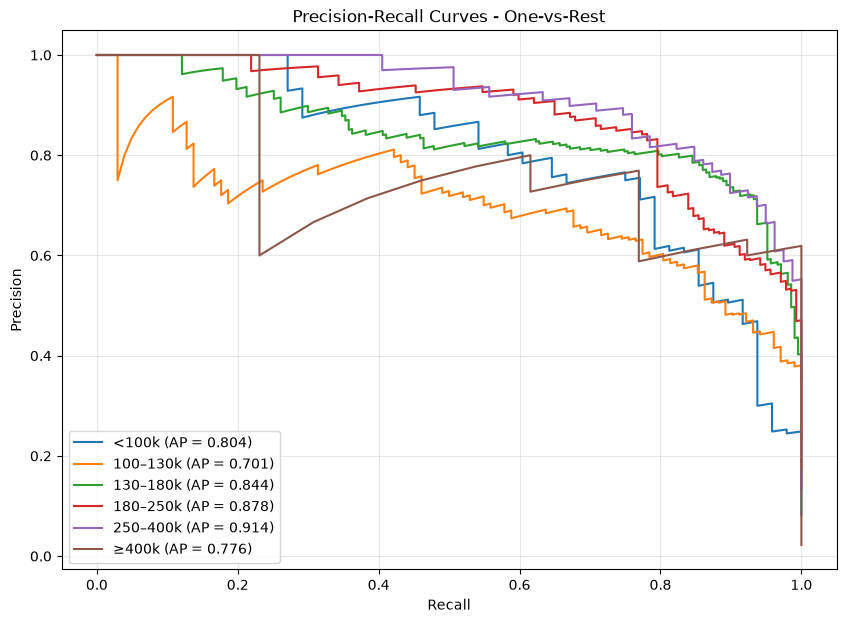

In [9]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(CLASS_NAMES):
    precision, recall, thresholds = precision_recall_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=f"{class_name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - One-vs-Rest")
plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.show()


## 8. Finding the Best Classification Thresholds

Until now, the model assigns each house to the class with the highest predicted probability. However, this does not necessarily give us the best macro-F1, especially because the price classes are imbalanced.

I want to investigate whether using different thresholds for each class can improve the predictions.

To do this, I first generate out-of-fold probabilities using 5-fold cross-validation. This means that every training observation receives predictions from a model that did not use that observation for training.

I then search for class-specific thresholds that improve the macro-F1 score.

- **Default prediction:** The class with the highest predicted probability.
- **Threshold-adjusted prediction:** The class with the highest probability after accounting for its individual threshold.

I compare the resulting macro-F1 scores to see whether adjusting the thresholds improves the classification.


In [10]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    XGBClassifier(random_state=42),
    X_train,
    y_train,
    cv=cv5,
    method="predict_proba"
)

print("OOF probabilities shape:", oof_prob.shape)

OOF probabilities shape: (2344, 6)


In [11]:
# Function to predict using class-specific thresholds
def predict_with_thresholds(probabilities, thresholds):
    adjusted_scores = probabilities - thresholds
    return np.argmax(adjusted_scores, axis=1)


# Start with equal thresholds (equivalent to normal argmax predictions)
best_thresholds = np.full(len(CLASS_NAMES), 0.5)

best_score = f1_score(
    y_train,
    predict_with_thresholds(oof_prob, best_thresholds),
    average="macro"
)

# Try different threshold values
candidates = np.linspace(0.05, 0.95, 19)

# Adjust one class at a time
for _ in range(3):
    for class_idx in range(len(CLASS_NAMES)):
        for threshold in candidates:
            trial_thresholds = best_thresholds.copy()
            trial_thresholds[class_idx] = threshold

            trial_pred = predict_with_thresholds(
                oof_prob, trial_thresholds
            )

            score = f1_score(
                y_train,
                trial_pred,
                average="macro"
            )

            if score > best_score:
                best_score = score
                best_thresholds = trial_thresholds

print("Best thresholds:")
for name, threshold in zip(CLASS_NAMES, best_thresholds):
    print(f"{name}: {threshold:.3f}")

print("\nDefault OOF macro-F1:",
      round(f1_score(y_train, np.argmax(oof_prob, axis=1), average="macro"), 3))

print("Threshold-adjusted OOF macro-F1:",
      round(best_score, 3))

Best thresholds:
<100k: 0.950
100–130k: 0.500
130–180k: 0.750
180–250k: 0.600
250–400k: 0.950
≥400k: 0.500

Default OOF macro-F1: 0.723
Threshold-adjusted OOF macro-F1: 0.744


In [12]:
# Apply the thresholds to the test probabilities
y_pred_threshold = predict_with_thresholds(
    y_prob, best_thresholds
)

print("Default test macro-F1:",
      round(f1_score(y_test, y_pred, average="macro"), 3))

print("Threshold-adjusted test macro-F1:",
      round(f1_score(y_test, y_pred_threshold, average="macro"), 3))

Default test macro-F1: 0.748
Threshold-adjusted test macro-F1: 0.736



## 9. Visualizing the First and Best Tree

I also want to take a look at the decision trees created by XGBoost to get a better understanding of how the model makes its predictions.

Since we have six price classes, each boosting iteration generates six individual trees, one for each class.

I first visualize the initial tree from the baseline model. To identify the best iteration, I train a separate model with early stopping using an additional validation subset taken from the training data.

Early stopping monitors the validation loss and stops training when it no longer improves for a specified number of iterations.

For the visualization, I select the tree belonging to the first class in the best boosting iteration. This allows me to compare an initial tree with one from a later, best-performing iteration.


/Users/viragdiana/Documents/ml-lab/.venv/lib/python3.13/site-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


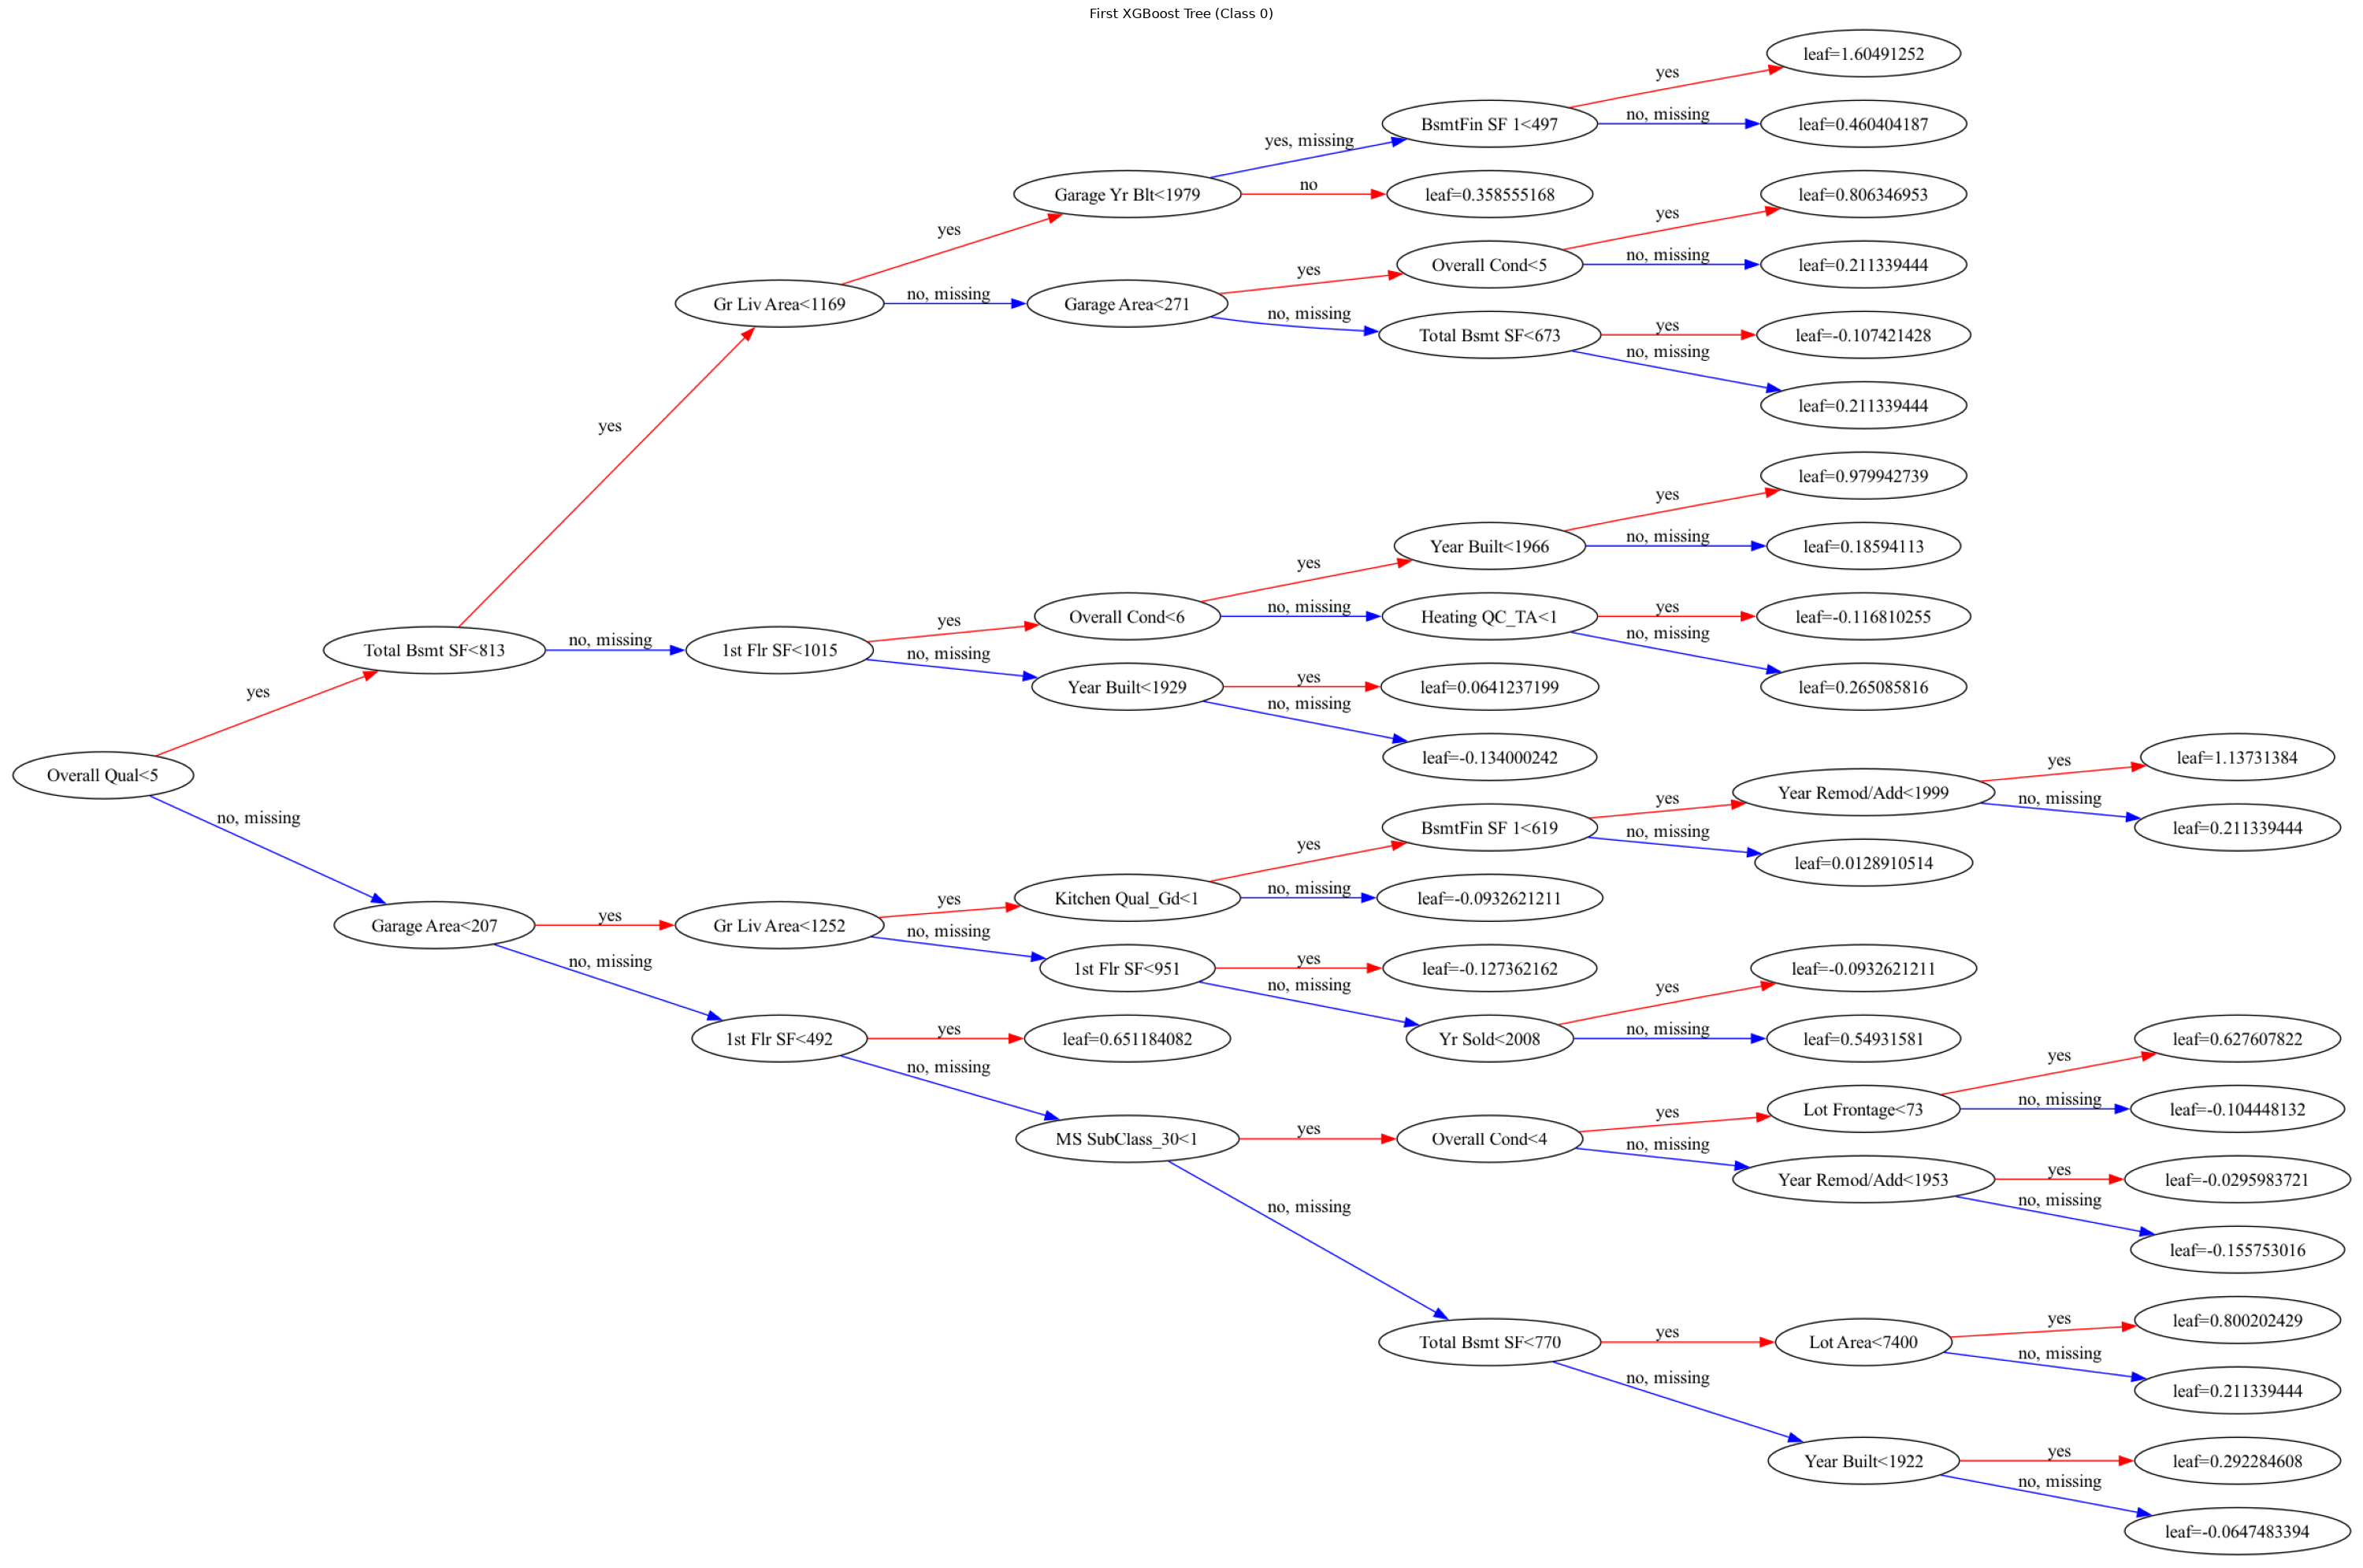

In [16]:
import matplotlib.pyplot as plt
from xgboost import plot_tree

fig, ax = plt.subplots(figsize=(35, 20))

plot_tree(
    baseline,
    num_trees=0,
    rankdir="LR",
    ax=ax
)

ax.set_title("First XGBoost Tree (Class 0)")
plt.tight_layout()
plt.show()